# Avaliação Visual e Comparativa de Taxonomias (Linear Probing - Dataset v3)

Este notebook valida visualmente e numericamente os melhores modelos identificados no benchmark de Linear Probing sobre os vetores do **DINOv2** (`apx2-bzsou-v3`).

As funções gerais de carregamento e manipulação de taxonomias e dados estão em `scripts/utils/data_utils.py`, enquanto os pipelines de Linear Probing e relatórios estão em `scripts/utils/linear_probing.py`. Os relatórios consolidados (`.json` e `.md`) e as matrizes de confusão são salvos automaticamente em `data/reports/avaliacao_taxonomias/`.

## 1. Configuração e Carregamento dos Dados

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

if os.getcwd().endswith('notebooks'):
    os.chdir('..')

from scripts.utils.data_utils import carregar_dados
from scripts.utils.linear_probing import avaliar_cenario

dados = carregar_dados(
    data_dir='data/processed/apx2-bzsou-v3',
    raw_dir='data/raw/apx2-bzsou-v3'
)
print(f"Dados carregados: Treino={len(dados['y_train'])} | Validação={len(dados['y_valid'])} | Teste={len(dados['y_test'])} imagens.")

Dados carregados: Treino=524 | Validação=150 | Teste=75 imagens.


## 2. Cenário 1: As 5 Classes Originais (Baseline dando "errado")

Demonstra o comportamento do classificador padrão quando tentamos separar todas as 5 classes brutas sem balanceamento: o modelo chuta `Adequada` na maioria dos casos e zera o *recall* de `Parcialmente Adequado`.


CENÁRIO 1: 5 CLASSES ORIGINAIS (BASELINE MLP)
Modelo: MLP (256) | Pré-proc: raw | Undersampling: Nenhum
Treino (após balanceamento) -> Adequada: 284 | Parcial: 88 | Inadequada: 37 | Sem calçada: 67 | Não id.: 48

--- Resultados no conjunto de VALIDAÇÃO (150 amostras) ---
Acurácia Geral: 0.6733 | Balanced Accuracy: 0.4959 | Macro F1: 0.5228

                 precision    recall  f1-score   support

   Adequada (0)       0.71      0.92      0.80        76
    Parcial (1)       0.40      0.26      0.32        23
 Inadequada (2)       0.90      0.50      0.64        18
Sem calçada (3)       0.79      0.71      0.75        21
    Não id. (4)       0.14      0.08      0.11        12

       accuracy                           0.67       150
      macro avg       0.59      0.50      0.52       150
   weighted avg       0.65      0.67      0.64       150


--- Resultados no conjunto de TESTE (75 amostras) ---
Acurácia Geral: 0.5867 | Balanced Accuracy: 0.3829 | Macro F1: 0.4021

               

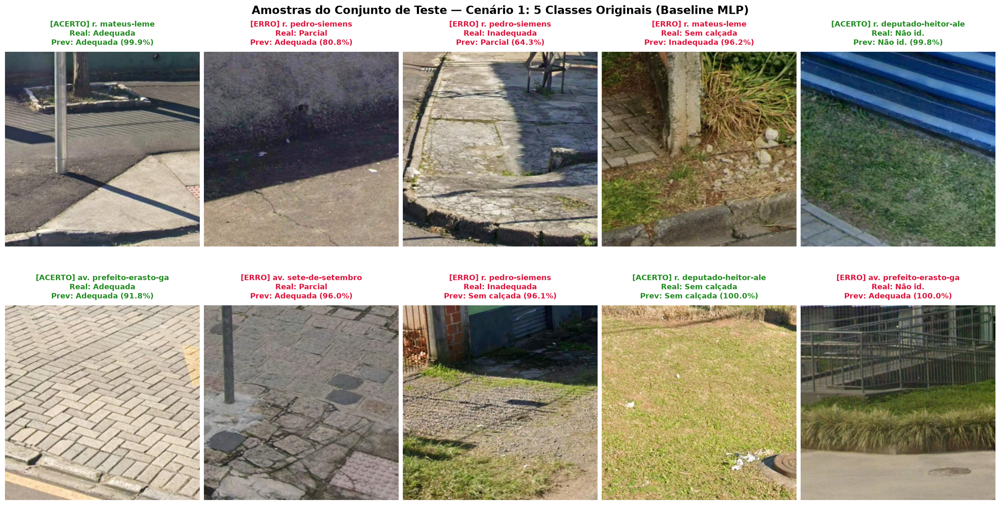

In [2]:
clf_5classes = avaliar_cenario('01_5classes_baseline', dados)


## 3. Cenário 2: 4 Classes com Não Identificável (`Inadequada + Sem calçada` unidas)

Une `Inadequada` e `Sem calçada` em uma única classe crítica e aplica `L2 + PCA(64)` com *undersampling* (`teto=70`). O F1 da classe crítica salta para **0.82**, mantendo `Não identificável` (**0.70**).


CENÁRIO 2: 4 CLASSES COM NÃO IDENTIFICÁVEL (INADEQUADA + SEM CALÇADA UNIDAS)
Modelo: SVC RBF (C=3.0, balanced) | Pré-proc: l2_pca64 | Undersampling: 70
Treino (após balanceamento) -> Adequada: 70 | Parcial: 70 | Inad.+SemCalçada: 70 | Não id.: 48

--- Resultados no conjunto de VALIDAÇÃO (150 amostras) ---
Acurácia Geral: 0.6000 | Balanced Accuracy: 0.5423 | Macro F1: 0.5244

                      precision    recall  f1-score   support

        Adequada (0)       0.81      0.67      0.73        76
         Parcial (1)       0.30      0.65      0.41        23
Inad.+SemCalçada (2)       0.87      0.51      0.65        39
         Não id. (3)       0.29      0.33      0.31        12

            accuracy                           0.60       150
           macro avg       0.57      0.54      0.52       150
        weighted avg       0.71      0.60      0.63       150


--- Resultados no conjunto de TESTE (75 amostras) ---
Acurácia Geral: 0.6267 | Balanced Accuracy: 0.6503 | Macro F1: 0.622

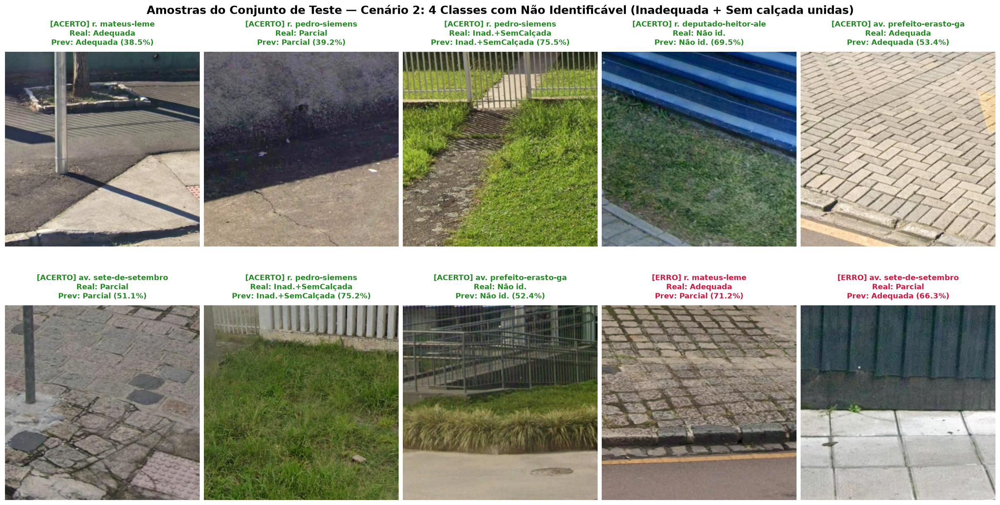

In [3]:
clf_4classes = avaliar_cenario('02_4classes_com_naoid', dados)


## 4. Cenário 3: 3 Classes sem Não Identificável (`Adequada` | `Com Defeito` | `Sem calçada`)

Remove a classe de ruído (`Não identificável`) e agrupa `Parcial + Inadequada` como calçadas com defeito estrutural, diferenciando-as de locais sem calçada.


CENÁRIO 3: 3 CLASSES SEM NÃO IDENTIFICÁVEL (ADEQUADA | COM DEFEITO | SEM CALÇADA)
Modelo: Random Forest (100, balanced) | Pré-proc: l2_pca64 | Undersampling: 100
Treino (após balanceamento) -> Adequada: 100 | Com Defeito: 100 | Sem calçada: 67

--- Resultados no conjunto de VALIDAÇÃO (138 amostras) ---
Acurácia Geral: 0.7681 | Balanced Accuracy: 0.7837 | Macro F1: 0.7851

                 precision    recall  f1-score   support

   Adequada (0)       0.85      0.74      0.79        76
Com Defeito (1)       0.61      0.80      0.69        41
Sem calçada (2)       0.94      0.81      0.87        21

       accuracy                           0.77       138
      macro avg       0.80      0.78      0.79       138
   weighted avg       0.79      0.77      0.77       138


--- Resultados no conjunto de TESTE (64 amostras) ---
Acurácia Geral: 0.7188 | Balanced Accuracy: 0.7231 | Macro F1: 0.7117

                 precision    recall  f1-score   support

   Adequada (0)       0.90      0.70   

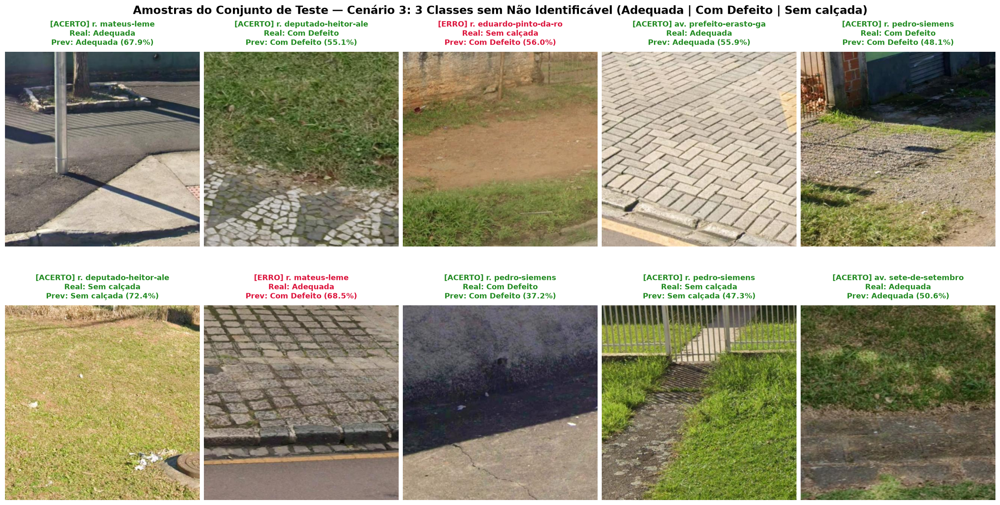

In [4]:
clf_3classes_sem_naoid = avaliar_cenario('03_3classes_sem_naoid', dados)


## 5. Cenário 4: 3 Classes com Não Identificável (`Adequada` | `Inadequada Geral` | `Não id.`)

Configuração voltada para o pipeline de produção: mantém a classe `Não identificável` para filtrar obstruções de câmera e agrupa qualquer inconformidade em `Inadequada Geral` (**78.7% de Acurácia** e **0.85 de F1** em Inadequada Geral).


CENÁRIO 4: 3 CLASSES COM NÃO IDENTIFICÁVEL (ADEQUADA | INADEQUADA GERAL | NÃO ID.)
Modelo: MLP (128, alpha=0.5, early_stopping) | Pré-proc: l2_std | Undersampling: Nenhum
Treino (após balanceamento) -> Adequada: 284 | Inadequada Geral: 192 | Não id.: 48

--- Resultados no conjunto de VALIDAÇÃO (150 amostras) ---
Acurácia Geral: 0.7200 | Balanced Accuracy: 0.5845 | Macro F1: 0.5978

                      precision    recall  f1-score   support

        Adequada (0)       0.76      0.84      0.80        76
Inadequada Geral (1)       0.69      0.66      0.68        62
         Não id. (2)       0.43      0.25      0.32        12

            accuracy                           0.72       150
           macro avg       0.63      0.58      0.60       150
        weighted avg       0.71      0.72      0.71       150


--- Resultados no conjunto de TESTE (75 amostras) ---
Acurácia Geral: 0.7867 | Balanced Accuracy: 0.7147 | Macro F1: 0.7341

                      precision    recall  f1-score 

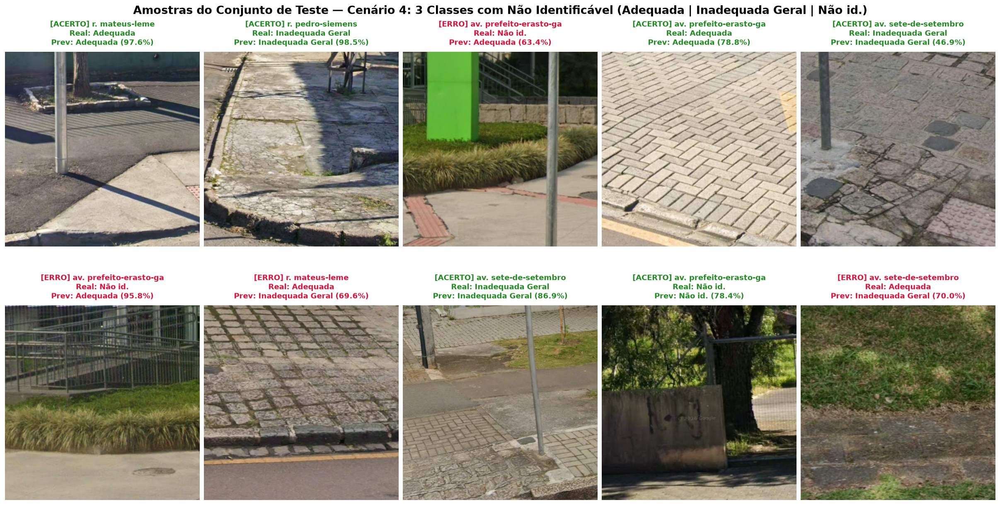

In [5]:
clf_3classes_com_naoid = avaliar_cenario('04_3classes_com_naoid', dados)


## 6. Cenário 5: 2 Classes sem Não Identificável (`Transitável` vs `Crítica`)

Classificação binária de criticidade severa: separa calçadas transitáveis (`Adequada + Parcial`) de trechos críticos (`Inadequada + Sem calçada`), atingindo **90.6% de Acurácia** e **91.8% de Balanced Accuracy**.


CENÁRIO 5: 2 CLASSES BINÁRIA CRÍTICA SEM NÃO IDENTIFICÁVEL (TRANSITÁVEL VS CRÍTICA)
Modelo: Regressão Logística (C=0.5, balanced) | Pré-proc: l2_pca64 | Undersampling: 100
Treino (após balanceamento) -> Transitável: 100 | Crítica (Inad+SemCalc): 100

--- Resultados no conjunto de VALIDAÇÃO (138 amostras) ---
Acurácia Geral: 0.8768 | Balanced Accuracy: 0.8675 | Macro F1: 0.8535

                            precision    recall  f1-score   support

           Transitável (0)       0.94      0.89      0.91        99
Crítica (Inad+SemCalc) (1)       0.75      0.85      0.80        39

                  accuracy                           0.88       138
                 macro avg       0.84      0.87      0.85       138
              weighted avg       0.88      0.88      0.88       138


--- Resultados no conjunto de TESTE (64 amostras) ---
Acurácia Geral: 0.8906 | Balanced Accuracy: 0.9070 | Macro F1: 0.8744

                            precision    recall  f1-score   support

           Tr

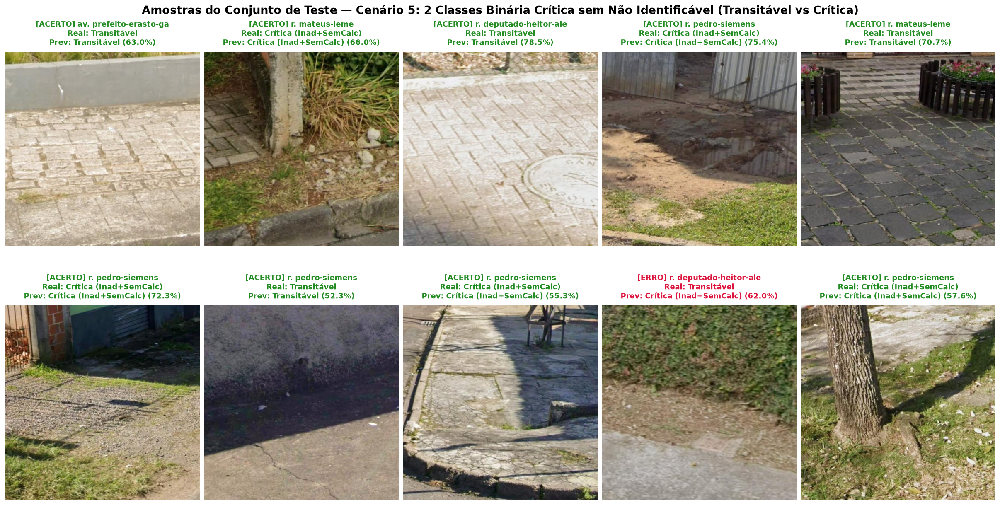

In [6]:
clf_2classes = avaliar_cenario('05_2classes_sem_naoid', dados)
